In [1]:
from __future__ import annotations

import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
import torch
from torch import nn

from probly.evaluation.active_learning import (
    BADGEQuery,
    MarginSampling,
    RandomQuery,
    active_learning_steps,
    compute_accuracy,
    compute_ece,
    compute_nauc,
    from_dataset,
)

SEED = 42
INITIAL_SIZE = 30
QUERY_SIZE = 30
N_ITERATIONS = 15
TRAIN_EPOCHS = 30
LEARNING_RATE = 1e-2

In [2]:
X, y = load_digits(return_X_y=True)
x_train_np, x_test_np, y_train_np, y_test_np = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=SEED,
)

x_train = torch.from_numpy(x_train_np).float()
y_train = torch.from_numpy(y_train_np).long()
x_test = torch.from_numpy(x_test_np).float()
y_test = torch.from_numpy(y_test_np).long()

Badge Estimator implementation

In [3]:
class TorchBadgeEstimator:
    """Two-layer MLP with an ``embed`` method for BADGE."""

    def __init__(self, n_features: int, n_classes: int) -> None:
        self._n_features = n_features
        self._n_classes = n_classes
        self._backbone: nn.Sequential | None = None
        self._head: nn.Linear | None = None

    def _build(self) -> tuple[nn.Sequential, nn.Linear]:
        backbone = nn.Sequential(nn.Linear(self._n_features, 64), nn.ReLU())
        head = nn.Linear(64, self._n_classes)
        return backbone, head

    def fit(self, x: torch.Tensor, y: torch.Tensor) -> None:
        self._backbone, self._head = self._build()
        model = nn.Sequential(self._backbone, self._head)
        optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
        loss_fn = nn.CrossEntropyLoss()
        model.train()
        for _ in range(TRAIN_EPOCHS):
            optimizer.zero_grad()
            loss_fn(model(x), y).backward()
            optimizer.step()

    @torch.no_grad()
    def predict(self, x: torch.Tensor) -> torch.Tensor:
        return self._head(self._backbone(x)).argmax(dim=1)  # type: ignore[misc]

    @torch.no_grad()
    def predict_proba(self, x: torch.Tensor) -> torch.Tensor:
        return torch.softmax(self._head(self._backbone(x)), dim=1)  # type: ignore[misc]

    @torch.no_grad()
    def embed(self, x: torch.Tensor) -> torch.Tensor:
        """Return 64-dim penultimate-layer features for BADGE."""
        return self._backbone(x)  # type: ignore[return-value]

Active Learning:

In [4]:
torch.manual_seed(SEED)

strategies = {
    "BADGE": BADGEQuery(seed=SEED),
    "Margin": MarginSampling(),
    "Random": RandomQuery(seed=SEED),
}

results: dict[str, dict] = {}

for name, strategy in strategies.items():
    pool = from_dataset(
        x_train,
        y_train,
        x_test,
        y_test,
        initial_size=INITIAL_SIZE,
        seed=SEED,
    )
    estimator = TorchBadgeEstimator(n_features=x_train.shape[1], n_classes=10)

    accuracies: list[float] = []
    eces: list[float] = []
    labeled_sizes: list[int] = []

    for state in active_learning_steps(
        pool,
        estimator,
        strategy,
        query_size=QUERY_SIZE,
        n_iterations=N_ITERATIONS,
    ):
        preds = state.estimator.predict(state.pool.x_test)
        probs = state.estimator.predict_proba(state.pool.x_test)
        accuracies.append(compute_accuracy(preds, state.pool.y_test))
        eces.append(compute_ece(probs, state.pool.y_test))
        labeled_sizes.append(state.pool.n_labeled)

    # NAUC (normalized area under the accuracy curve) summarizes how quickly
    # a strategy reaches good accuracy. Higher is better.
    nauc = compute_nauc(accuracies)
    results[name] = {
        "accuracies": accuracies,
        "eces": eces,
        "labeled_sizes": labeled_sizes,
    }
    print(f"{name:8s}  final acc: {accuracies[-1]:.3f}  ECE: {eces[-1]:.3f}  NAUC: {nauc:.3f}")

BADGE     final acc: 0.972  ECE: 0.019  NAUC: 0.944
Margin    final acc: 0.961  ECE: 0.035  NAUC: 0.946
Random    final acc: 0.953  ECE: 0.020  NAUC: 0.911


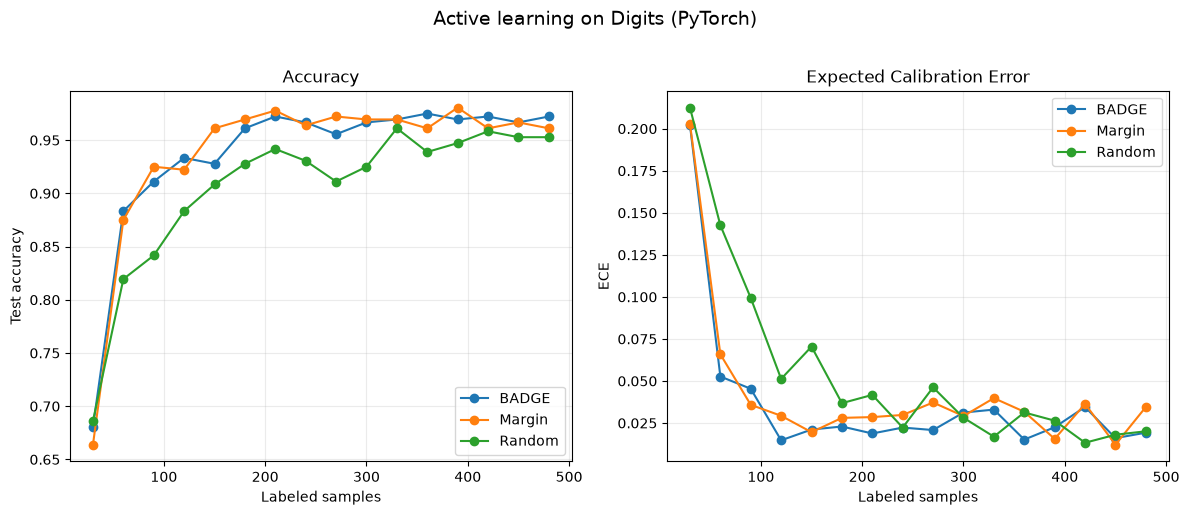

In [5]:
fig, (ax_acc, ax_ece) = plt.subplots(1, 2, figsize=(12, 5))

for name, data in results.items():
    ax_acc.plot(data["labeled_sizes"], data["accuracies"], marker="o", label=name)
    ax_ece.plot(data["labeled_sizes"], data["eces"], marker="o", label=name)

ax_acc.set_xlabel("Labeled samples")
ax_acc.set_ylabel("Test accuracy")
ax_acc.set_title("Accuracy")
ax_acc.legend()
ax_acc.grid(alpha=0.25)

ax_ece.set_xlabel("Labeled samples")
ax_ece.set_ylabel("ECE")
ax_ece.set_title("Expected Calibration Error")
ax_ece.legend()
ax_ece.grid(alpha=0.25)

fig.suptitle("Active learning on Digits (PyTorch)", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()